# 과정 지도와 학습 규칙

**이 노트북에서 할 일**

1. 과정 지도를 출력해 지금 배우는 Ch 1이 어디에 있는지 확인합니다.
2. 상품 합계를 먼저 예상하고, 컴퓨터가 계산한 값과 비교합니다.
3. 수량 하나만 바꿔 다시 예상하고 비교한 뒤 실행 기록을 남깁니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 모델 호출은 0번이고 비용은 들지 않습니다.
실행 시간은 1분 이내입니다. Python 3.12 커널에서 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

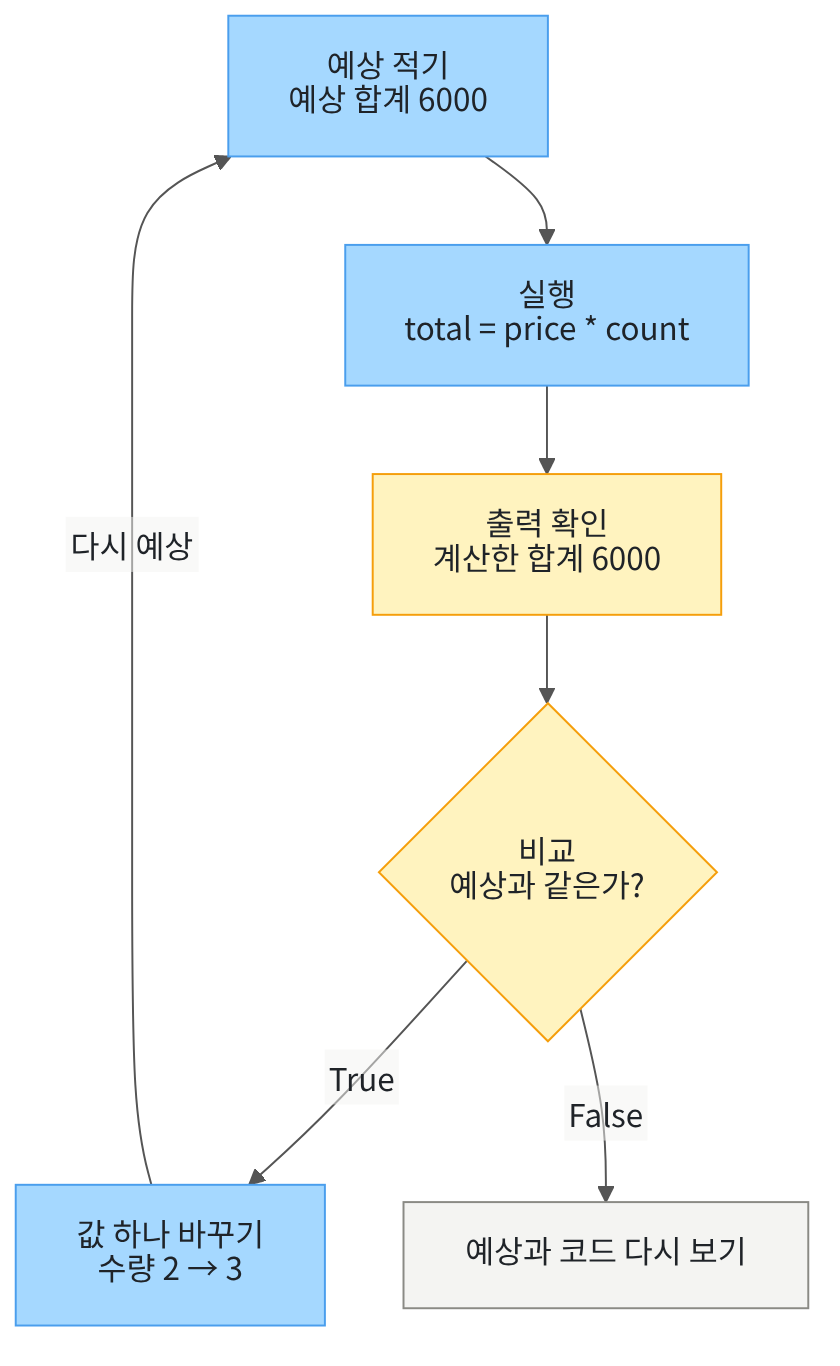

위에서 아래로 읽습니다. 파란 상자는 우리가 하는 행동이고, 노란 상자는 결과를 확인하는 행동입니다.
비교 결과가 `True`이면 값 하나를 바꾸고 다시 예상 적기 상자로 이어집니다.

## 1. 준비

이 절은 설치할 패키지가 없습니다. 첫 셀은 노트북을 실행하는 Python 버전을 확인합니다.
셀을 고른 뒤 `Shift+Enter`를 누르면 그 셀이 실행되고 다음 셀로 넘어갑니다.
실행 도구를 준비하는 방법은 2절과 3절에서 배웁니다.

첫 줄의 `import`는 Python에 들어 있는 기능 묶음을 불러오는 줄입니다. 자세한 뜻은 Ch 2에서 배웁니다.
이름 뒤에 괄호를 붙여 부르는 기능을 함수라고 합니다. 함수가 계산해 내놓는 값을 반환값이라고 합니다.
따옴표로 감싼 글을 문자열이라고 합니다.

In [1]:
# 이 노트북을 실행하는 Python 버전을 확인합니다
import platform

# python_version()은 "3.12.13" 같은 버전 문자열을 반환합니다
python_version = platform.python_version()
is_python_312 = python_version.startswith("3.12")
print("Python 버전:", python_version)
print("3.12 버전인가:", is_python_312)

Python 버전: 3.12.13
3.12 버전인가: True


**결과 읽기** — Python 버전이 3.12로 시작하고 `True`가 보이면 준비가 된 것입니다.
버전의 마지막 숫자는 컴퓨터마다 다를 수 있습니다.

## 2. 과정 지도 출력하기

과정 전체는 Part 여덟 개로 나뉩니다. 각 Part의 이름과 챕터 범위를 목록에 담아 출력합니다.
목록(list)은 값 여러 개를 순서대로 담는 자료입니다. 장보기 메모에 살 것을 한 줄씩 적는 모습과 비슷합니다.
아래 셀에서는 대괄호 `[ ]` 안에 문자열 여덟 개를 쉼표로 나눠 넣습니다.

In [2]:
# 과정의 Part 여덟 개를 순서대로 목록에 담습니다
course_map = [
    "Part 1 개발 기반 · Ch 1~5",
    "Part 2 LangChain과 프롬프트 · Ch 6~8",
    "Part 3 RAG · Ch 9~12",
    "Part 4 그래프·평가·안정화 · Ch 13~16",
    "Part 5 Agent 입문 · Ch 17~20",
    "Part 6 Agent 개발 · Ch 21~29",
    "Part 7 서비스화와 배포 · Ch 30~34",
    "Part 8 AI 페어 개발 · Ch 35~41",
]
# len()은 목록에 든 값의 개수를 반환합니다
print("Part 수:", len(course_map))

Part 수: 8


**결과 읽기** — Part 수가 `8`입니다. 목록에 넣은 문자열 개수와 같습니다.

다음 셀은 목록의 값을 앞에서부터 하나씩 꺼내 번호와 함께 출력합니다.
반복문 `for`는 목록의 값마다 들여 쓴 줄을 한 번씩 실행합니다.
번호는 1에서 시작해 한 줄을 출력할 때마다 1씩 늘립니다.

In [3]:
# 목록의 값을 하나씩 꺼내 번호와 함께 출력합니다
number = 1
for part in course_map:
    print(number, part)
    # 다음 줄에 쓸 번호를 1 늘립니다
    number = number + 1

1 Part 1 개발 기반 · Ch 1~5
2 Part 2 LangChain과 프롬프트 · Ch 6~8
3 Part 3 RAG · Ch 9~12
4 Part 4 그래프·평가·안정화 · Ch 13~16
5 Part 5 Agent 입문 · Ch 17~20
6 Part 6 Agent 개발 · Ch 21~29
7 Part 7 서비스화와 배포 · Ch 30~34
8 Part 8 AI 페어 개발 · Ch 35~41


**결과 읽기** — 첫 줄은 `1 Part 1 개발 기반 · Ch 1~5`입니다. 지금 배우는 Ch 1이 이 구간에 있습니다.
마지막 줄은 `8 Part 8 AI 페어 개발 · Ch 35~41`입니다.
모델을 처음 호출하는 곳은 Part 2의 Ch 6입니다. Part 1에서는 모델을 부르지 않습니다.

## 3. 결과를 먼저 예상하기

가게에서 3000원짜리 상품 2개를 산다고 해 봅니다. 계산하기 전에 합계를 먼저 적습니다.
머릿속으로 곱하면 6000원입니다.
아래 셀의 등호 `=`는 오른쪽 값을 왼쪽 이름에 저장합니다. 이름은 단가 `price`, 수량 `count`, 예상 합계 `prediction` 세 개입니다.

In [4]:
# 계산하기 전에 단가, 수량, 예상 합계를 적습니다
price = 3000
count = 2
prediction = 6000
print("단가:", price)
print("수량:", count)
print("예상 합계:", prediction)

단가: 3000
수량: 2
예상 합계: 6000


**결과 읽기** — 단가 `3000`, 수량 `2`, 예상 합계 `6000`이 출력됐습니다.
아직 곱셈은 하지 않았습니다. 예상 합계는 우리가 손으로 적은 값입니다.

## 4. 실행하고 출력 확인하기

이제 컴퓨터가 합계를 계산합니다. 곱셈 기호는 `*`입니다.
식 `price * count`는 저장해 둔 단가와 수량을 곱합니다. 계산한 값은 `total`이라는 이름에 저장합니다.

In [5]:
# 단가와 수량을 곱해 실제 합계를 계산합니다
total = price * count
print("계산한 합계:", total)

계산한 합계: 6000


**결과 읽기** — 계산한 합계가 `6000`입니다.
셀이 오류 없이 실행됐다는 사실만으로는 부족합니다. 이 값이 우리가 원한 값인지 다음 셀에서 비교합니다.

## 5. 예상과 비교하기

두 값이 같은지 묻는 기호는 등호 두 개 `==`입니다. 등호 하나는 저장, 등호 두 개는 비교입니다.
비교 결과는 참을 뜻하는 `True`나 거짓을 뜻하는 `False` 중 하나입니다.

In [6]:
# 계산한 합계와 예상 합계가 같은지 비교합니다
same = total == prediction
print("예상과 같은가:", same)

예상과 같은가: True


**결과 읽기** — `True`가 나왔습니다. 계산한 합계와 예상 합계가 모두 6000이라는 뜻입니다.

예상을 잘못 적으면 어떻게 될까요? 수량을 잘못 세어 5000원으로 예상했다고 해 봅니다.
실행 전에 먼저 예상합니다. 계산한 합계는 그대로 6000이므로 `False`가 나올 것입니다.

In [7]:
# 틀리게 적은 예상과 계산한 합계를 비교합니다
wrong_prediction = 5000
wrong_same = total == wrong_prediction
print("틀린 예상:", wrong_prediction)
print("예상과 같은가:", wrong_same)

틀린 예상: 5000
예상과 같은가: False


**결과 읽기** — 틀린 예상 `5000`과 비교하자 `False`가 나왔습니다.
비교가 거짓이면 예상과 코드 중 한쪽이 틀린 것입니다. 이번에는 예상을 틀리게 적었고 코드는 그대로입니다.

## 6. 검사 줄 넣기

출력에서 `True`를 눈으로 찾는 대신 검사 줄을 넣을 수 있습니다.
검사 줄은 `assert` 뒤에 조건을 적습니다. 조건이 참이면 아무것도 출력하지 않고 다음 줄로 넘어갑니다.
조건이 거짓이면 실행을 멈추고 `AssertionError` 오류를 보여 줍니다. 그래서 검사 뒤에 확인용 문장을 한 줄 출력합니다.

In [8]:
# 합계가 예상과 다르면 이 줄에서 실행을 멈춥니다
assert total == prediction
print("검사 통과, 합계:", total)

검사 통과, 합계: 6000


**결과 읽기** — `검사 통과, 합계: 6000`이 출력됐습니다. 검사 줄에서 멈추지 않고 다음 줄까지 실행됐다는 뜻입니다.
조건이 거짓이라 실행이 멈추는 장면은 이번에 실행하지 않았습니다.

## 7. 값 하나만 바꿔 보기

단가는 그대로 두고 수량만 2에서 3으로 바꿉니다. 이번에도 실행 전에 예상부터 적습니다.
3000원짜리 3개이므로 예상 합계는 9000원입니다.
바꾼 값은 새 이름 `new_count`에 담습니다. 앞에서 쓴 `count` 값은 비교를 위해 그대로 둡니다.

In [9]:
# 수량만 3으로 바꾸고, 계산 전에 새 예상 합계를 적습니다
new_count = 3
new_prediction = 9000
print("단가:", price)
print("바꾼 수량:", new_count)
print("새 예상 합계:", new_prediction)

단가: 3000
바꾼 수량: 3
새 예상 합계: 9000


**결과 읽기** — 단가 `3000`은 그대로이고, 바꾼 수량은 `3`, 새 예상 합계는 `9000`입니다.

같은 곱셈으로 새 합계를 계산하고 새 예상과 비교합니다.

In [10]:
# 같은 곱셈으로 새 합계를 계산하고 예상과 비교합니다
new_total = price * new_count
new_same = new_total == new_prediction
print("새 합계:", new_total)
print("예상과 같은가:", new_same)

새 합계: 9000
예상과 같은가: True


**결과 읽기** — 새 합계는 `9000`이고 비교 결과는 `True`입니다.
두 실행에서 바꾼 값은 수량 하나뿐입니다. 그래서 합계가 달라진 원인을 수량이라고 말할 수 있습니다.

## 8. 실행 기록 남기기

두 번의 실행을 기록으로 남깁니다. 기록에는 바꾼 입력, 예상, 실제 출력을 함께 적습니다.
「잘 됨」만 적으면 무엇이 맞았는지 나중에 알 수 없습니다. 두 합계의 차이도 계산해 둡니다.

In [11]:
# 두 번의 실행을 수량·예상·실제 값으로 기록합니다
difference = new_total - total
print("실행 1 | 수량", count, "| 예상", prediction, "| 실제", total)
print("실행 2 | 수량", new_count, "| 예상", new_prediction, "| 실제", new_total)
print("두 합계의 차이:", difference)

실행 1 | 수량 2 | 예상 6000 | 실제 6000
실행 2 | 수량 3 | 예상 9000 | 실제 9000
두 합계의 차이: 3000


**결과 읽기** — 실행 1은 `수량 2 | 예상 6000 | 실제 6000`입니다. 실행 2는 `수량 3 | 예상 9000 | 실제 9000`입니다.
두 합계의 차이는 `3000`으로 단가와 같습니다. 이번 두 실행에서는 수량이 1 늘자 합계가 단가만큼 늘었습니다.

## 정리

- 실행 전에 입력과 예상 결과를 먼저 적습니다.
- 실행 뒤에는 `==` 비교나 검사 줄 `assert`로 예상과 출력을 맞춰 봅니다.
- 값 하나만 바꾸고 같은 순서를 반복하면 결과가 달라진 원인을 말할 수 있습니다.

이번에 확인한 계산은 단가 3000에 수량 2와 3을 곱한 두 경우입니다. 할인이나 배송비가 붙는 계산은 실행하지 않았습니다.
다음 절에서는 편집기와 터미널을 준비합니다.